# 01. Исследование данных для AIOps early warning

Этот notebook нужен как исследовательская глава о данных. Здесь мы не выбираем финальную модель и не доказываем, что финальный контур уже необходим. Задача проще и важнее: понять, из чего реально состоит `raw_data/`, как из него собирается `strict contract`, какие распределения получаются у логов, KPI, workload и target, и какие проблемы данных потом должны стать проверками в `02_baseline_pipeline.ipynb`.

Поэтому логика такая: сначала смотрим на источник и контракт как на объект исследования, затем проверяем split, модальности, KPI/log-сигнал, target imbalance и предсобытийную динамику. Только в конце формулируем гипотезу о pipeline: какие решения в `02` должны быть не вкусовыми, а вытекающими из данных.


In [11]:
from __future__ import annotations

import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd()
RAW_DATA = PROJECT_ROOT / "raw_data"
CONTRACT_PATH = PROJECT_ROOT / "dashboard" / "artifacts" / "contract" / "strict_intensity_contract.csv.gz"

SPLIT_ORDER = ["train", "validation", "test"]
STATE_LABELS = {"normal": "Норма", "warning": "Предупреждение", "risk": "Риск"}
HORIZON_SECONDS = [30, 60, 120, 300]

PALETTE = {
    "blue": "#2F6F9F",
    "teal": "#2A9D8F",
    "green": "#5A8F3C",
    "orange": "#D98032",
    "red": "#B84A4A",
    "gray": "#6E7781",
    "light_gray": "#D8DEE4",
}

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update(
    {
        "figure.dpi": 130,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "axes.titleweight": "bold",
    }
)


def run_command(cmd: list[str]) -> None:
    result = subprocess.run(cmd, cwd=PROJECT_ROOT, text=True, capture_output=True)
    if result.stdout:
        print(result.stdout)
    if result.returncode != 0:
        if result.stderr:
            print(result.stderr)
        raise RuntimeError(f"Command failed: {' '.join(cmd)}")


def load_contract() -> pd.DataFrame:
    if not CONTRACT_PATH.exists():
        run_command([sys.executable, "-m", "dashboard.pipeline.build_contract", "--raw-data", str(RAW_DATA)])
    frame = pd.read_csv(CONTRACT_PATH)
    for col in ["window_ts", "window_end", "run_start", "run_end", "fail_start", "event_anchor"]:
        if col in frame.columns:
            frame[col] = pd.to_datetime(frame[col], errors="coerce")
    return frame


def add_eda_horizons(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    if "minutes_before_fail" not in out.columns:
        return out
    lead_sec = pd.to_numeric(out["minutes_before_fail"], errors="coerce") * 60.0
    for horizon in HORIZON_SECONDS:
        out[f"eda_horizon_{horizon}s"] = ((lead_sec >= 0) & (lead_sec <= horizon)).astype(int)
    return out


def target_label(name: str) -> str:
    labels = {
        "y_warning": "Горизонт 180 с",
        "horizon_30s": "Горизонт 30 с",
        "horizon_60s": "Горизонт 60 с",
        "horizon_120s": "Горизонт 120 с",
        "horizon_300s": "Горизонт 300 с",
    }
    if name.startswith("eda_horizon_"):
        horizon = name.replace("eda_horizon_", "").replace("s", "")
        return f"Горизонт {horizon} с"
    return labels.get(name, name)


def format_percent(value: float) -> str:
    if pd.isna(value):
        return "н/д"
    return f"{100 * value:.1f}%"


def kpi_feature_columns(frame: pd.DataFrame) -> list[str]:
    service_cols = {
        "kpi_available",
        "kpi_feature_count",
        "kpi_series_available",
        "kpi_avail_ratio",
        "kpi_recency_sec",
    }
    return [c for c in frame.columns if c.startswith("kpi_") and "__" in c and c not in service_cols]


def kpi_family(col: str) -> str:
    for family in ["cpustat", "iostat", "memstat", "netstat", "vmstat", "jvms"]:
        if f"__{family}__" in col:
            return family
    return "other"


def robust_scale_by_column(frame: pd.DataFrame) -> pd.DataFrame:
    scaled = frame.copy().astype(float)
    for col in scaled.columns:
        series = scaled[col]
        q1, q3 = series.quantile([0.25, 0.75])
        denom = q3 - q1
        if not np.isfinite(denom) or denom == 0:
            denom = series.std()
        if not np.isfinite(denom) or denom == 0:
            denom = 1.0
        scaled[col] = (series - series.median()) / denom
    return scaled.clip(-3, 3)


contract = load_contract()
eda = add_eda_horizons(contract)

target_cols = [c for c in ["y_warning"] if c in eda.columns]
eda_horizon_cols = [f"eda_horizon_{h}s" for h in HORIZON_SECONDS if f"eda_horizon_{h}s" in eda.columns]
all_target_cols = target_cols + eda_horizon_cols
kpi_cols = kpi_feature_columns(eda)
log_signal_cols = [
    c
    for c in [
        "macro_log_count",
        "micro_log_count",
        "macro_warn_count",
        "macro_error_count",
        "micro_warn_count",
        "micro_error_count",
        "macro_log_rate",
        "micro_log_rate",
        "micro_error_rate",
    ]
    if c in eda.columns
]

print(f"Strict contract: {contract.shape[0]:,} окон x {contract.shape[1]:,} колонок")
print(f"Workload: {contract['workload'].nunique() if 'workload' in contract else 0}")
print(f"Run_id: {contract['run_id'].nunique() if 'run_id' in contract else 0}")
print(f"KPI features: {len(kpi_cols):,}; log/count features: {len(log_signal_cols)}")


Strict contract: 2,883 окон x 1,132 колонок
Workload: 16
Run_id: 228
KPI features: 1,080; log/count features: 9


## 1. Что физически лежит в `raw_data/`

Начинать с target или модели опасно: можно не заметить, что исходник сам по себе неоднороден. Для AIOps это особенно важно, потому что разные workload создают разные профили нагрузки, длительности run и плотность событий. Если читать такие данные напрямую в каждом эксперименте, легко получить несколько несовместимых версий одного и того же датасета.

Сначала делаем инвентаризацию каталога. Нас интересуют не только размеры, но и сам факт, что данные приходят несколькими источниками: logs, KPI, сценарии, run-level файлы. Это объясняет, почему дальше понадобится единый contract-builder, а не набор локальных чтений CSV внутри baseline.


workload,Файлы,CSV,Log-файлы,KPI-файлы,Сценарии,"Размер, MB"
scan,2267,3,60,2204,29,263.8
aggregation,1147,6,35,1105,30,147.3
wordcount,1139,3,30,1105,29,88.5
graph_pagerank,1135,3,30,1102,29,128.9
rf,1135,3,30,1102,29,106.0
sleep,1135,3,30,1102,29,163.1
join,1135,3,30,1102,29,155.2
sort,1135,3,30,1102,29,77.8
nweight,1127,2,23,1102,30,1459.0
terasort,1102,3,35,1064,29,227.2


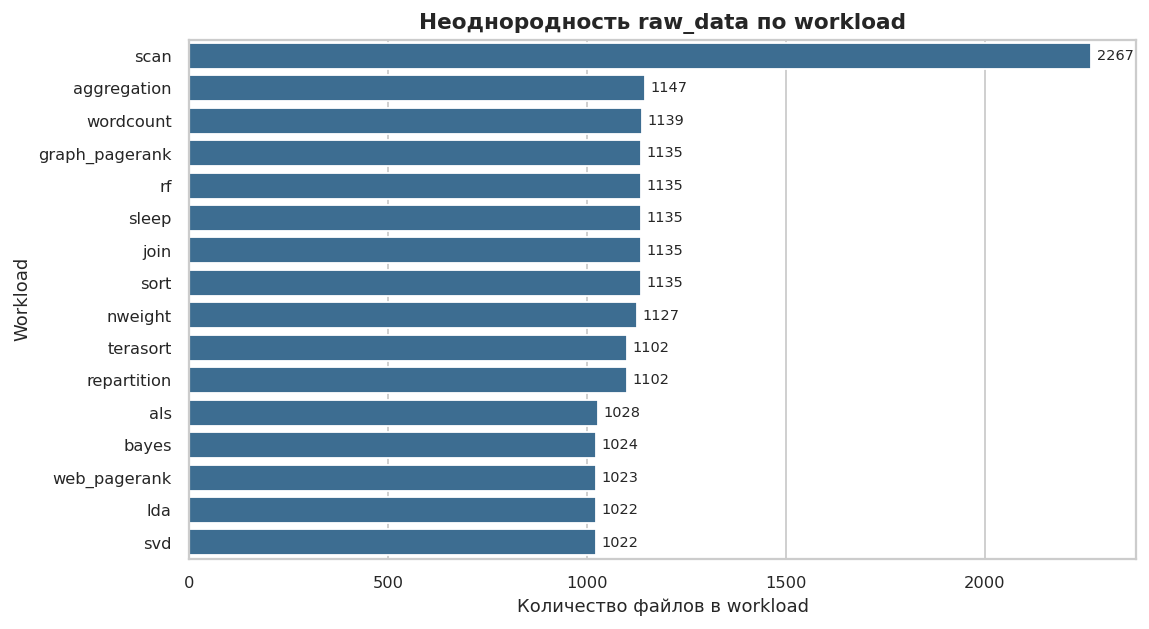

In [12]:
raw_rows = []
if RAW_DATA.exists():
    for workload_dir in sorted(p for p in RAW_DATA.iterdir() if p.is_dir() and not p.name.startswith('.')):
        files = [p for p in workload_dir.rglob("*") if p.is_file()]
        lower_parts = [(p, {part.lower() for part in p.parts}) for p in files]
        log_files = [p for p, parts in lower_parts if "logs" in parts or "mapred_logs" in parts or p.suffix.lower() == ".log"]
        kpi_files = [p for p, parts in lower_parts if "kpis" in parts]
        csv_files = [p for p in files if p.suffix.lower() == ".csv"]
        scenarios = set()
        kpi_root = workload_dir / "kpis"
        if kpi_root.exists():
            scenarios.update(p.name for p in kpi_root.iterdir() if p.is_dir())
        log_root = workload_dir / "mapred_logs"
        if log_root.exists():
            scenarios.update(p.name for p in log_root.iterdir() if p.is_dir())
        raw_rows.append(
            {
                "workload": workload_dir.name,
                "Файлы": len(files),
                "CSV": len(csv_files),
                "Log-файлы": len(log_files),
                "KPI-файлы": len(kpi_files),
                "Сценарии": len(scenarios),
                "Размер, MB": sum(p.stat().st_size for p in files) / (1024**2),
            }
        )

raw_summary = pd.DataFrame(raw_rows).sort_values("Файлы", ascending=False)
display(
    raw_summary[["workload", "Файлы", "CSV", "Log-файлы", "KPI-файлы", "Сценарии", "Размер, MB"]]
    .style.hide(axis="index")
    .format({"Размер, MB": "{:.1f}"})
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=raw_summary, y="workload", x="Файлы", color=PALETTE["blue"], ax=ax)
ax.set_title("Неоднородность данных по типам нагрузки")
ax.set_xlabel("Количество файлов по типам нагрузки")
ax.set_ylabel("Тип нагрузки")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3, fontsize=8)
plt.tight_layout()
plt.show()


В каталоге видно 16 рабочих workload, но они не одинаковые по объему. Большинство workload лежит примерно в диапазоне 1.0-1.1 тыс. файлов, а `scan` выделяется почти вдвое большим числом файлов - 2267. По размеру на диске сильнее всего выделяется `nweight`: около 1.46 GB, хотя по количеству файлов он не самый большой. Это полезное различие: количество окон, вес исходника и характер нагрузки не совпадают один к одному.

Практический вывод для следующего notebook здесь вполне конкретный. Данные нельзя читать как один плоский CSV без provenance: workload, сценарий, run и источник признаков должны сохраняться в contract. Иначе baseline в `02` будет зависеть от того, какие файлы случайно попали в локальную сборку, а не от качества pipeline.


## 2. Strict contract как исследовательская таблица

`strict contract` в этом notebook используется не как готовый ответ, а как нормализованная таблица наблюдений. Он фиксирует единицу анализа - окно наблюдения - и собирает рядом identity, split, признаки логов, KPI, доступность модальностей и target-поля. Это удобно для EDA: можно говорить о распределениях на одном уровне детализации, не смешивая run-level и file-level факты.

Важный момент: contract не отменяет raw data. Он делает raw data сравнимым. Поэтому в `02` pipeline должен проверять, что именно этот contract является входом для baseline, predictions и workload breakdown.


In [ ]:
column_groups = [
    {
        "Группа": "Identity / provenance",
        "Примеры": ", ".join([c for c in ["workload", "scenario", "run_id", "window_ts", "split", "state"] if c in eda.columns]),
        "Колонок": sum(c in eda.columns for c in ["workload", "scenario", "run_id", "window_ts", "split", "state"]),
        "Зачем смотрим": "контроль домена, окна и честного разбиения",
    },
    {
        "Группа": "Modality availability",
        "Примеры": ", ".join([c for c in ["log_available", "kpi_available", "has_both_modalities", "kpi_avail_ratio"] if c in eda.columns]),
        "Колонок": sum(c in eda.columns for c in ["log_available", "kpi_available", "has_both_modalities", "kpi_avail_ratio"]),
        "Зачем смотрим": "понимание, какие источники реально доступны в окнах",
    },
    {
        "Группа": "Log features",
        "Примеры": ", ".join(log_signal_cols[:5]),
        "Колонок": len(log_signal_cols),
        "Зачем смотрим": "плотность событий и возможный сигнал в логах",
    },
    {
        "Группа": "KPI features",
        "Примеры": ", ".join(kpi_cols[:3]),
        "Колонок": len(kpi_cols),
        "Зачем смотрим": "числовая динамика нагрузки и деградации",
    },
    {
        "Группа": "Targets / lead time",
        "Примеры": ", ".join(target_cols + [c for c in ["minutes_before_fail", "warning_intensity", "risk_intensity"] if c in eda.columns]),
        "Колонок": len(target_cols) + sum(c in eda.columns for c in ["minutes_before_fail", "warning_intensity", "risk_intensity"]),
        "Зачем смотрим": "плотность классов и временная близость к событию",
    },
]

display(pd.DataFrame(column_groups).style.hide(axis="index"))

contract_summary = pd.DataFrame(
    [
        {"Показатель": "Окна", "Значение": f"{len(eda):,}"},
        {"Показатель": "Workload", "Значение": eda["workload"].nunique() if "workload" in eda.columns else "н/д"},
        {"Показатель": "Run_id", "Значение": eda["run_id"].nunique() if "run_id" in eda.columns else "н/д"},
        {"Показатель": "Train / validation / test", "Значение": " / ".join(str(int((eda['split'] == s).sum())) for s in SPLIT_ORDER if "split" in eda.columns)},
        {"Показатель": "KPI feature columns", "Значение": f"{len(kpi_cols):,}"},
        {"Показатель": "Log feature columns", "Значение": len(log_signal_cols)},
    ]
)
display(contract_summary.style.hide(axis="index"))


После сборки contract получается 2883 окна и 1132 колонки. Основная масса признаков - KPI: больше тысячи числовых колонок против небольшого набора агрегатов по логам. Это уже говорит о перекосе данных: KPI-модальность богаче по размерности, а логовая модальность компактнее и сильнее зависит от наличия событий в окне.

Полезная информация здесь не в самом числе колонок, а в структуре таблицы. Contract одновременно хранит `workload`, `run_id`, split, состояние окна, доступность модальностей и target-поля. Значит, в `02` можно построить pipeline, который проверяет не только качество baseline, но и целостность эксперимента: одинаковый вход, одинаковые split-правила, одинаковый формат predictions и metrics.


## 3. Split и workload: достаточно ли честной опоры для оценки

Для дипломной AIOps-системы split нельзя воспринимать как техническую колонку. Если какой-то workload почти полностью попал в один split, метрики будут измерять перенос между доменами иначе, чем предполагается. Если workload представлены в split неравномерно, средний F1 может скрыть локальные провалы.

Поэтому здесь мы проверяем покрытие окон по workload и split. Это не финальная проверка leakage, но первый аргумент в пользу того, что в `02` нужны split sanity tests и отдельные workload metrics.


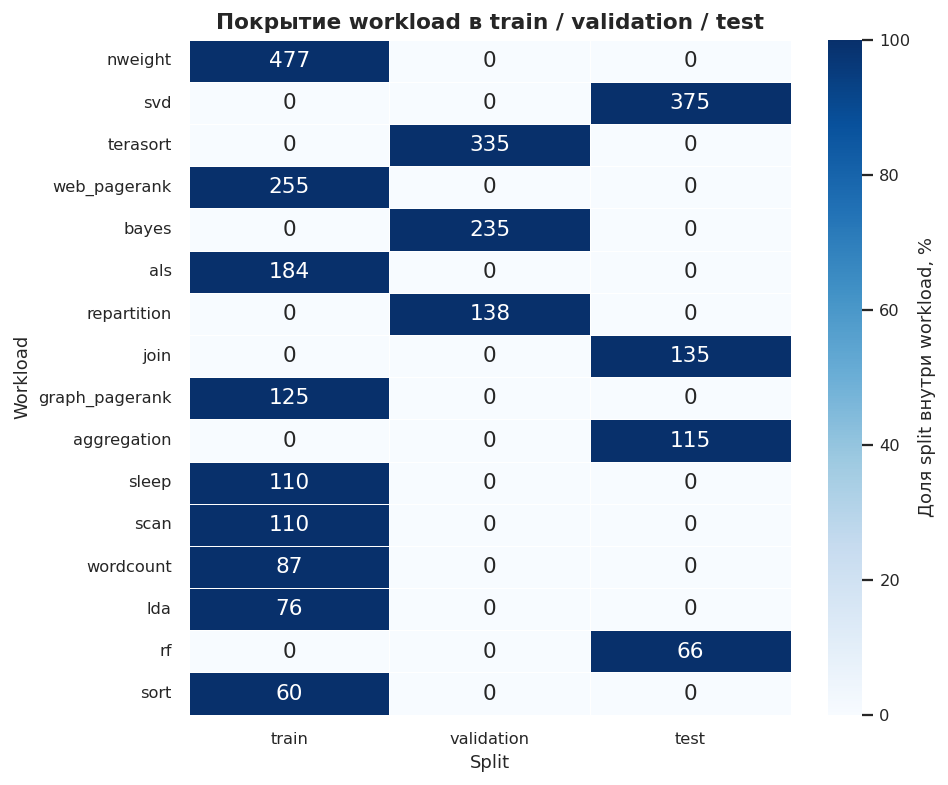

split,Окна,Доля
train,1484,51.5%
validation,708,24.6%
test,691,24.0%


In [14]:
if {"workload", "split"}.issubset(eda.columns):
    split_workload = eda.groupby(["workload", "split"], dropna=False).size().reset_index(name="Окна")
    workload_order = (
        split_workload.groupby("workload")["Окна"].sum().sort_values(ascending=False).index.tolist()
    )
    split_pivot = (
        split_workload.pivot(index="workload", columns="split", values="Окна")
        .reindex(index=workload_order, columns=SPLIT_ORDER)
        .fillna(0)
        .astype(int)
    )
    split_share = split_pivot.div(split_pivot.sum(axis=1), axis=0).fillna(0)

    fig, ax = plt.subplots(figsize=(7.5, 6.2))
    sns.heatmap(
        split_share * 100,
        annot=split_pivot,
        fmt="d",
        cmap="Blues",
        cbar_kws={"label": "Доля разбиения внутри типа нагрузки, %"},
        linewidths=0.5,
        linecolor="white",
        ax=ax,
    )
    ax.set_title("Покрытие типов нагрузки в обучении / валидации / тесте")
    ax.set_xlabel("Разбиение")
    ax.set_ylabel("Тип нагрузки")
    plt.tight_layout()
    plt.show()

    split_totals = eda["split"].value_counts().reindex(SPLIT_ORDER).rename_axis("split").reset_index(name="Окна")
    split_totals["Доля"] = split_totals["Окна"] / split_totals["Окна"].sum()
    display(split_totals.style.hide(axis="index").format({"Доля": "{:.1%}"}))
else:
    print("В contract нет колонок workload/split.")


На heatmap видно важную особенность текущего contract split: многие workload целиком находятся только в одном split. Например, `nweight`, `web_pagerank`, `als` и `graph_pagerank` попадают в train, `bayes`, `terasort` и `repartition` - в validation, а `svd`, `join` и `aggregation` - в test. Это не просто неравномерность, а почти workload-level разделение.

Такой split полезен как сигнал о доменной неоднородности, но он слишком сильно смешивает задачу раннего предупреждения с задачей переноса на другой workload. Поэтому в `02` нужен явный split protocol, а не слепое доверие колонке `split`. `stratified_by_workload` становится не декоративной настройкой, а способом сделать baseline более контролируемым; workload metrics при этом все равно остаются обязательными, потому что доменный эффект никуда не исчезает.


## 4. Доступность модальностей

Мультимодальная постановка выглядит естественно только пока мы предполагаем, что в каждом окне есть и KPI, и logs. Реальные данные часто хуже: лог может быть пустым, KPI могут быть неполными, а часть окна может иметь только признаки доступности. Это не ошибка, а свойство эксплуатационных данных.

Поэтому здесь проверяем, насколько часто доступны источники. Если доступность сама по себе коррелирует с target, `02` обязан иметь baseline `availability_only`: он покажет, нет ли в данных слишком простого shortcut. Если часть модальностей неполна, нужны отдельные log-only, KPI-only и fused проверки.


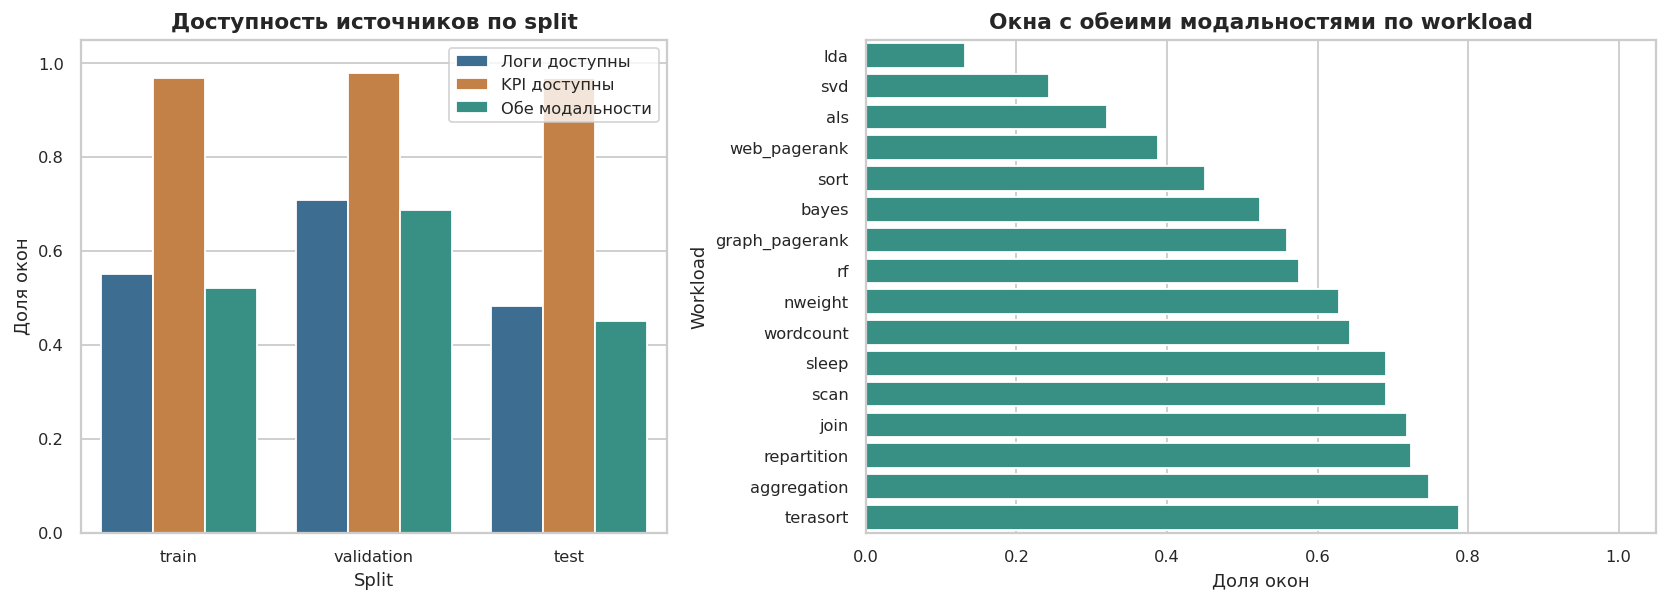

Признак,Доля окон
log_available,57.4%
kpi_available,97.1%
has_both_modalities,54.5%


In [15]:
availability_cols = [c for c in ["log_available", "kpi_available", "has_both_modalities"] if c in eda.columns]
if availability_cols and "split" in eda.columns:
    availability_split = (
        eda.groupby("split")[availability_cols]
        .mean()
        .reindex(SPLIT_ORDER)
        .reset_index()
        .melt(id_vars="split", var_name="Модальность", value_name="Доля окон")
    )
    availability_split["Модальность"] = availability_split["Модальность"].map(
        {
            "log_available": "Логи доступны",
            "kpi_available": "KPI доступны",
            "has_both_modalities": "Обе модальности",
        }
    )

    if "workload" in eda.columns:
        workload_availability = (
            eda.groupby("workload")[availability_cols]
            .mean()
            .sort_values(availability_cols[-1] if "has_both_modalities" in availability_cols else availability_cols[0])
        )
    else:
        workload_availability = pd.DataFrame()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.0, 1.35]})
    sns.barplot(
        data=availability_split,
        x="split",
        y="Доля окон",
        hue="Модальность",
        palette=[PALETTE["blue"], PALETTE["orange"], PALETTE["teal"]][: availability_split["Модальность"].nunique()],
        ax=axes[0],
    )
    axes[0].set_title("Доступность источников по разбиениям")
    axes[0].set_xlabel("Разбиение")
    axes[0].set_ylabel("Доля окон")
    axes[0].set_ylim(0, 1.05)
    axes[0].legend(title="")

    if not workload_availability.empty:
        plot_col = "has_both_modalities" if "has_both_modalities" in workload_availability.columns else availability_cols[0]
        sns.barplot(
            x=workload_availability[plot_col].values,
            y=workload_availability.index,
            color=PALETTE["teal"],
            ax=axes[1],
        )
        axes[1].set_title("Окна с обеими модальностями по типам нагрузки")
        axes[1].set_xlabel("Доля окон")
        axes[1].set_ylabel("Тип нагрузки")
        axes[1].set_xlim(0, 1.05)
    else:
        axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    display(
        eda[availability_cols]
        .mean()
        .rename("Доля окон")
        .reset_index()
        .rename(columns={"index": "Признак"})
        .style.hide(axis="index")
        .format({"Доля окон": "{:.1%}"})
    )
else:
    print("Колонки доступности модальностей отсутствуют.")


График доступности показывает асимметрию источников. KPI доступны почти всегда: около 97% окон. Логи доступны заметно хуже - примерно в 57% окон, а обе модальности одновременно есть только примерно в 55% окон. На test ситуация еще жестче: обе модальности доступны примерно в 45% окон, тогда как на validation - около 69%.

Это полезный результат, потому что он сразу ограничивает ожидания от fused-модели. Если почти половина test-окон не имеет полноценной пары logs+KPI, простое требование "мультимодальная модель должна всегда побеждать" становится некорректным. В `02` обязательно нужны `availability_only`, log-only, KPI-only и fused baseline: они покажут, где есть реальный сигнал, а где модель может опираться только на факт доступности источника.


## 5. Логовая модальность: плотность событий и шум

Логи в AIOps полезны не потому, что в них всегда есть явная строка "fail". Чаще они дают косвенный событийный контекст: меняется плотность сообщений, растут warning/error, появляются редкие компоненты. Но такой сигнал может быть очень шумным и зависеть от workload.

Здесь мы смотрим на распределение log-count признаков по состояниям окна. Если нормальные и предсобытийные окна сильно перекрываются, в `02` нельзя ожидать идеального log-only baseline. Зато нужно проверить, есть ли в логах хотя бы слабое разделение и сколько ложных тревог оно порождает.


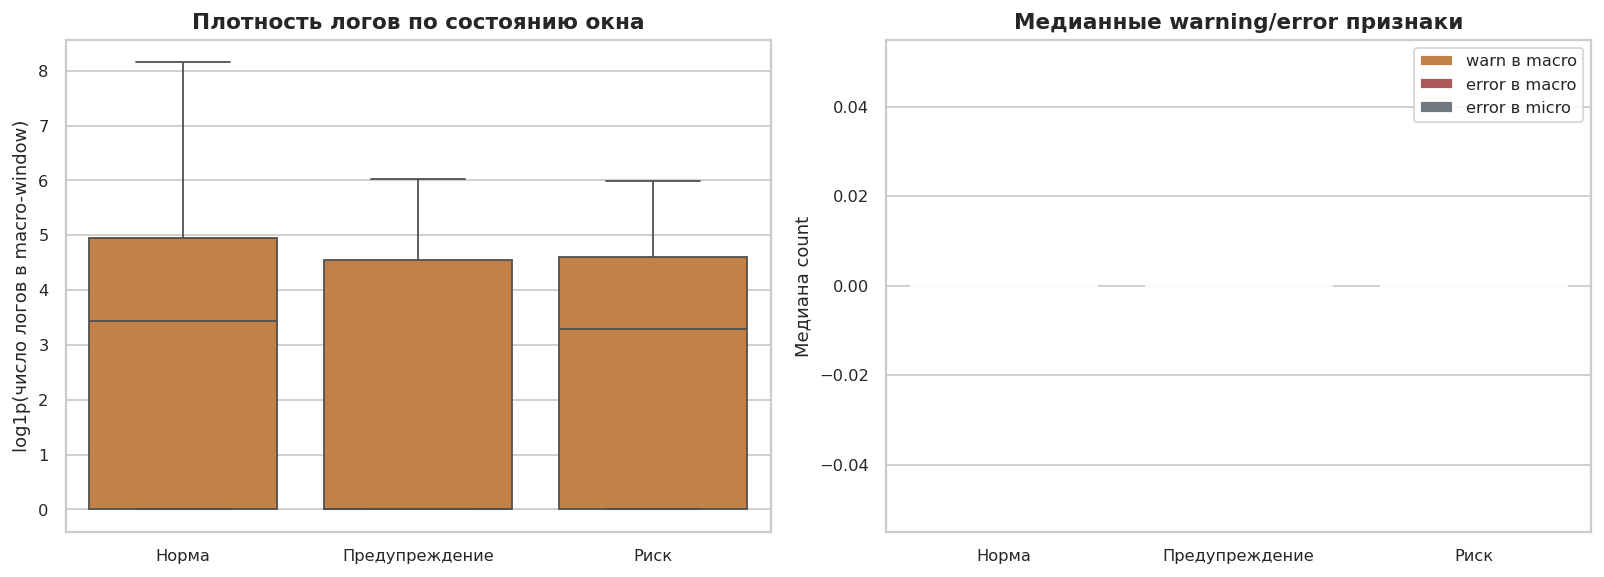

Состояние,Окна,Macro_log_median,Macro_log_q90,Macro_error_median
Норма,1469,30.0,284.2,0.0
Предупреждение,1123,0.0,246.8,0.0
Риск,291,26.0,267.0,0.0


In [16]:
if "state" in eda.columns and "macro_log_count" in eda.columns:
    log_frame = eda.copy()
    log_frame["Состояние"] = log_frame["state"].map(STATE_LABELS).fillna(log_frame["state"].astype(str))
    log_frame["log1p(macro_log_count)"] = np.log1p(pd.to_numeric(log_frame["macro_log_count"], errors="coerce"))

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
    sns.boxplot(
        data=log_frame,
        x="Состояние",
        y="log1p(macro_log_count)",
        order=["Норма", "Предупреждение", "Риск"],
        color=PALETTE["orange"],
        fliersize=2,
        ax=axes[0],
    )
    axes[0].set_title("Плотность логов по состоянию окна")
    axes[0].set_xlabel("")
    axes[0].set_ylabel("log1p(число логов в макроокне)")

    rate_cols = [c for c in ["macro_warn_count", "macro_error_count", "micro_error_count"] if c in log_frame.columns]
    if rate_cols:
        severity = (
            log_frame.groupby("Состояние")[rate_cols]
            .median()
            .reindex(["Норма", "Предупреждение", "Риск"])
            .reset_index()
            .melt(id_vars="Состояние", var_name="Признак", value_name="Медиана")
        )
        severity["Признак"] = severity["Признак"].map(
            {
                "macro_warn_count": "warn в macro",
                "macro_error_count": "error в macro",
                "micro_error_count": "error в micro",
            }
        )
        sns.barplot(
            data=severity,
            x="Состояние",
            y="Медиана",
            hue="Признак",
            palette=[PALETTE["orange"], PALETTE["red"], PALETTE["gray"]][: severity["Признак"].nunique()],
            ax=axes[1],
        )
        axes[1].set_title("Медианные признаки предупреждений и ошибок")
        axes[1].set_xlabel("")
        axes[1].set_ylabel("Медианное значение")
        axes[1].legend(title="")
    else:
        axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    log_stats = (
        log_frame.groupby("Состояние")
        .agg(
            Окна=("macro_log_count", "size"),
            Macro_log_median=("macro_log_count", "median"),
            Macro_log_q90=("macro_log_count", lambda s: s.quantile(0.90)),
            Macro_error_median=("macro_error_count", "median") if "macro_error_count" in log_frame else ("macro_log_count", "median"),
        )
        .reindex(["Норма", "Предупреждение", "Риск"])
        .reset_index()
    )
    display(log_stats.style.hide(axis="index").format({"Macro_log_median": "{:.1f}", "Macro_log_q90": "{:.1f}", "Macro_error_median": "{:.1f}"}))
else:
    print("Недостаточно колонок для анализа логовой модальности.")


In [ ]:
import ast

hades_blocks_path = PROJECT_ROOT / "dashboard" / "modeling" / "hades_blocks.py"
module_tree = ast.parse(hades_blocks_path.read_text(encoding="utf-8"))
severity_weight = {}
log_keywords = []
for node in module_tree.body:
    if isinstance(node, ast.Assign):
        names = [target.id for target in node.targets if isinstance(target, ast.Name)]
        if "SEVERITY_WEIGHT" in names:
            severity_weight = ast.literal_eval(node.value)
        if "LOG_KEYWORDS" in names:
            log_keywords = ast.literal_eval(node.value)

level_order = ["TRACE", "DEBUG", "INFO", "WARN", "WARNING", "ERROR", "FATAL"]
level_labels = {
    "TRACE": "TRACE",
    "DEBUG": "DEBUG",
    "INFO": "INFO",
    "WARN": "WARN",
    "WARNING": "WARNING",
    "ERROR": "ERROR",
    "FATAL": "FATAL",
}
level_group = {
    "TRACE": "Служебный шум",
    "DEBUG": "Служебный шум",
    "INFO": "Информационный фон",
    "WARN": "Предупреждение",
    "WARNING": "Предупреждение",
    "ERROR": "Ошибка",
    "FATAL": "Критический сбой",
}
severity_weights = pd.DataFrame(
    [
        {
            "Уровень": level_labels[level],
            "Базовый вес": float(severity_weight.get(level, 0.0)),
            "Группа": level_group[level],
        }
        for level in level_order
        if level in severity_weight
    ]
)
severity_weights["Уровень"] = pd.Categorical(severity_weights["Уровень"], categories=[level_labels[level] for level in level_order if level in severity_weight], ordered=True)
severity_weights = severity_weights.sort_values("Уровень")

fig, ax = plt.subplots(figsize=(7.8, 4.6))
sns.barplot(
    data=severity_weights,
    x="Базовый вес",
    y="Уровень",
    hue="Группа",
    dodge=False,
    palette={
        "Служебный шум": PALETTE["gray"],
        "Информационный фон": PALETTE["blue"],
        "Предупреждение": PALETTE["orange"],
        "Ошибка": PALETTE["red"],
        "Критический сбой": "#7A1F1F",
    },
    ax=ax,
)
for row_idx, row in severity_weights.reset_index(drop=True).iterrows():
    ax.text(row["Базовый вес"] + 0.08, row_idx, f"{row['Базовый вес']:.1f}", va="center", fontsize=9, color="#333333")

ax.set_title("Весовые коэффициенты уровней важности в логовой ветке")
ax.set_xlabel("Базовый severity-вес")
ax.set_ylabel("Уровень лога")
ax.set_xlim(0, max(float(severity_weights["Базовый вес"].max()) * 1.18, 1.0))
ax.legend(title="Смысл уровня", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.text(
    0,
    -0.92,
    f"Итоговый score события: severity_weight(level) + keyword_score; словарных триггеров: {len(log_keywords)}",
    fontsize=9,
    color=PALETTE["gray"],
)
plt.tight_layout()
plt.show()


Распределение логов получилось не таким, каким его хотелось бы видеть в идеальной демонстрации. У `warning` медиана `macro_log_count` равна нулю, у `normal` - около 30, у `risk` - около 26. Error- и warn-счетчики почти везде имеют нулевые медианы. Это означает, что логовая модальность не дает простого правила вида "больше логов или ошибок значит ближе к сбою".

График весов уровней важности показывает другую часть логики логовой ветки. `INFO`, `DEBUG` и `TRACE` почти не должны сами по себе двигать модель к тревоге, тогда как `WARN/WARNING`, `ERROR` и особенно `FATAL` получают больший базовый severity-вес. Это не обученный attention-вес, а инженерный prior в parser/selection layer: перед embedding-энкодером редкие и опасные сообщения получают больше шансов попасть в последовательность окна.

Именно поэтому этот блок полезен для `02` и `03`. Log-only baseline в `02` проверяет, есть ли в таком шумном источнике самостоятельный сигнал, а финальная логовая ветка в `03` уже использует не только счетчики, но и последовательность отобранных логовых событий с учетом severity, редкости и близости к текущему окну.


## 6. KPI-модальность: масштаб, семейства признаков и domain shift

KPI дают более непрерывное описание поведения системы: CPU, disk, memory, network, scheduler-like признаки. Но числовые признаки опасны своим масштабом. Один workload может иметь высокий CPU как норму, а другой - как признак деградации. Поэтому перед baseline нужно понять, насколько KPI-профили различаются между workload.

Сначала считаем семейства KPI-признаков, затем берем несколько представительских метрик и сравниваем их workload-медианы. Это не выбор финальной нормализации, а причина, почему в `02` preprocessing должен быть проверяемым шагом, а не молчаливой строкой кода.


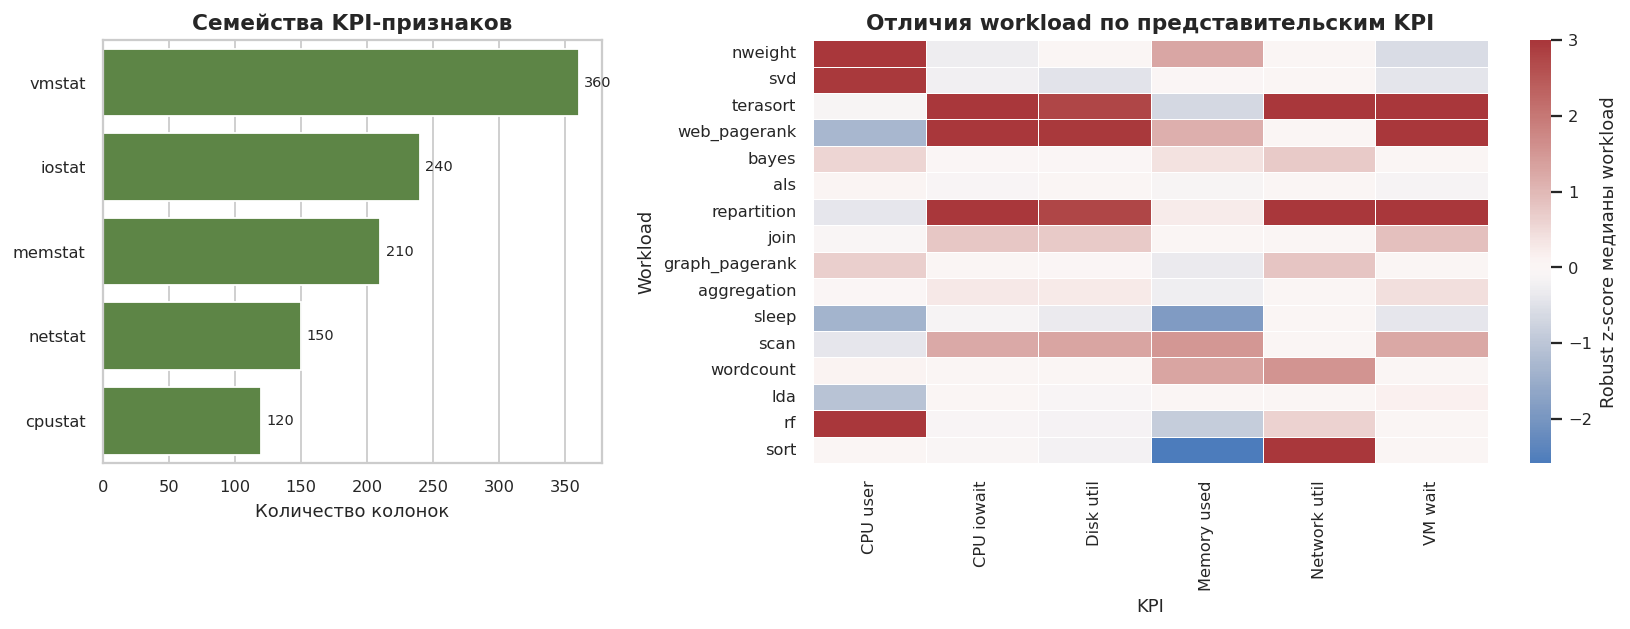

Семейство KPI,Колонок
vmstat,360
iostat,240
memstat,210
netstat,150
cpustat,120


In [17]:
if kpi_cols and "workload" in eda.columns:
    family_counts = (
        pd.Series([kpi_family(c) for c in kpi_cols])
        .value_counts()
        .rename_axis("Семейство KPI")
        .reset_index(name="Колонок")
    )

    metric_tokens = {
        "cpustat__user__mean_dim__mean": "CPU user",
        "cpustat__iowait__mean_dim__mean": "CPU iowait",
        "iostat__util__mean_dim__mean": "Disk util",
        "memstat__memused__mean_dim__mean": "Memory used",
        "netstat__ifutil__mean_dim__mean": "Network util",
        "vmstat__wa__mean_dim__mean": "VM wait",
    }
    selected = {}
    for token, label in metric_tokens.items():
        matches = [c for c in kpi_cols if token in c]
        if matches:
            selected[matches[0]] = label

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [0.8, 1.35]})
    sns.barplot(data=family_counts, y="Семейство KPI", x="Колонок", color=PALETTE["green"], ax=axes[0])
    axes[0].set_title("Семейства KPI-признаков")
    axes[0].set_xlabel("Количество колонок")
    axes[0].set_ylabel("")
    axes[0].bar_label(axes[0].containers[0], fmt="%.0f", padding=3, fontsize=8)

    if selected:
        workload_metric = eda.groupby("workload")[list(selected.keys())].median(numeric_only=True)
        workload_metric = workload_metric.loc[eda["workload"].value_counts().index]
        scaled = robust_scale_by_column(workload_metric).rename(columns=selected)
        sns.heatmap(
            scaled,
            cmap="vlag",
            center=0,
            linewidths=0.35,
            linecolor="white",
            cbar_kws={"label": "Robust z-score медианы workload"},
            ax=axes[1],
        )
        axes[1].set_title("Отличия типов нагрузки по представительским KPI")
        axes[1].set_xlabel("KPI")
        axes[1].set_ylabel("Тип нагрузки")
    else:
        axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    display(family_counts.style.hide(axis="index"))
else:
    print("KPI-признаки или workload отсутствуют.")


KPI-модальность, наоборот, богата и структурирована: больше всего признаков приходится на `vmstat`, затем идут `iostat`, `memstat`, `netstat` и `cpustat`. Но тепловая карта представительских KPI показывает сильные различия между workload. Например, `rf`, `nweight` и `svd` выделяются по CPU user, а `web_pagerank`, `terasort` и `repartition` - по disk/IO wait признакам. Для части сетевых признаков несколько workload оказываются почти на нуле, а другие резко уходят вверх.

Это не доказывает, что конкретная нормализация уже выбрана правильно, но доказывает, что без нормализации сравнение будет хрупким. В `02` preprocessing должен быть самостоятельной частью pipeline: raw-признаки, deviation-признаки и workload-aware normalization нужны не для красоты, а чтобы модель не принимала нормальный для данного workload уровень нагрузки за предвестник инцидента.


## 7. Распределение целевых каналов и горизонтов раннего предупреждения

Теперь переходим к целевым каналам. В аналитическом контуре `01` мы фиксируем `y_warning` как канал предупреждения (в интерпретации горизонта 180 с) и добавляем исследовательские горизонты `30/60/120/300 с`, рассчитанные из `minutes_before_fail`. Это нужно, чтобы заранее оценить, насколько раннее предупреждение усложняет задачу.

Главный вопрос здесь практический: одинаково ли сложны каналы? Если плотность положительных окон заметно различается между split и горизонтами, одна общая метрика будет искажать картину.


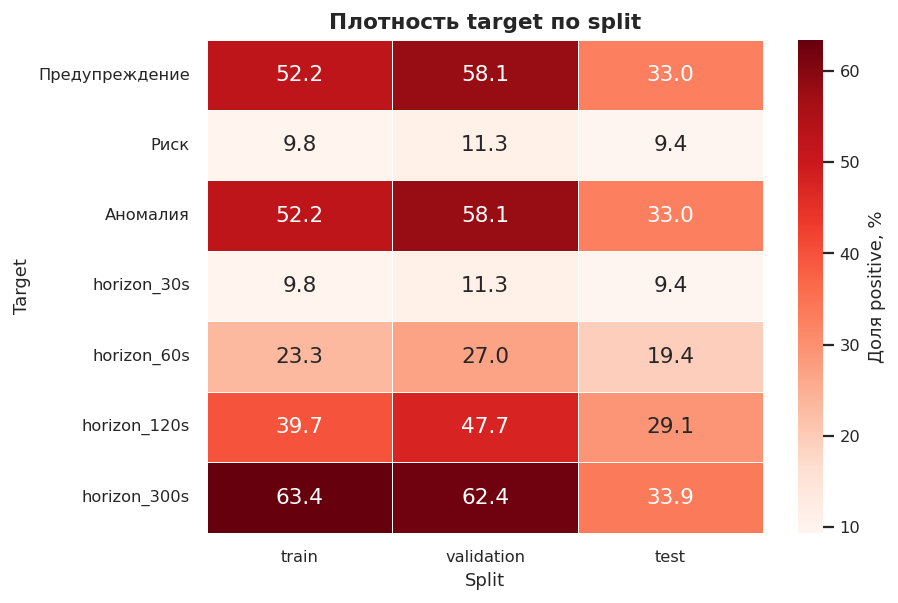

Target,Доля positive
Предупреждение,49.0%
Риск,10.1%
Аномалия,49.0%
horizon_30s,10.1%
horizon_60s,23.3%
horizon_120s,39.1%
horizon_300s,56.1%


In [18]:
if all_target_cols and "split" in eda.columns:
    target_split = (
        eda.groupby("split")[all_target_cols]
        .mean()
        .reindex(SPLIT_ORDER)
        .T
    )
    target_split.index = [target_label(c) for c in target_split.index]

    fig, ax = plt.subplots(figsize=(7.2, 4.8))
    sns.heatmap(
        target_split * 100,
        annot=True,
        fmt=".1f",
        cmap="Reds",
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Доля positive, %"},
        ax=ax,
    )
    ax.set_title("Плотность целевых каналов по разбиениям")
    ax.set_xlabel("Разбиение")
    ax.set_ylabel("Целевой канал")
    plt.tight_layout()
    plt.show()

    target_rates = (
        eda[all_target_cols]
        .mean()
        .rename("Доля positive")
        .reset_index()
        .rename(columns={"index": "Target"})
    )
    target_rates["Target"] = target_rates["Target"].map(target_label)
    display(target_rates.style.hide(axis="index").format({"Доля positive": "{:.1%}"}))
else:
    print("Target columns отсутствуют.")


In [ ]:
if all_target_cols:
    positive_counts = (
        eda[all_target_cols]
        .apply(pd.to_numeric, errors="coerce")
        .fillna(0)
        .sum()
        .rename("Положительных окон")
        .reset_index()
        .rename(columns={"index": "target"})
    )
    positive_counts["Положительных окон"] = positive_counts["Положительных окон"].astype(int)
    positive_counts["Доля окон"] = positive_counts["Положительных окон"] / max(len(eda), 1)
    positive_counts["Целевой канал"] = positive_counts["target"].map(target_label)
    positive_counts = positive_counts.sort_values("Положительных окон", ascending=True)

    fig, ax = plt.subplots(figsize=(7.6, 4.4))
    sns.barplot(
        data=positive_counts,
        x="Положительных окон",
        y="Целевой канал",
        color=PALETTE["blue"],
        ax=ax,
    )
    max_count = max(int(positive_counts["Положительных окон"].max()), 1)
    for row_idx, row in positive_counts.reset_index(drop=True).iterrows():
        label = f"{int(row['Положительных окон']):,} ({row['Доля окон']:.1%})".replace(",", " ")
        ax.text(
            row["Положительных окон"] + max_count * 0.015,
            row_idx,
            label,
            va="center",
            fontsize=9,
            color="#333333",
        )

    ax.set_title("Количество положительных окон по целевым каналам")
    ax.set_xlabel("Количество positive-окон")
    ax.set_ylabel("Целевой канал")
    ax.set_xlim(0, max_count * 1.22)
    plt.tight_layout()
    plt.show()
else:
    print("Целевые каналы отсутствуют.")


Распределение подтверждает, что каналы действительно разной сложности. Heatmap показывает различия между split, а столбчатый график добавляет абсолютный масштаб задачи: короткий горизонт `30 с` содержит меньше всего положительных окон, `60 с` и `120 с` занимают промежуточное положение, а `300 с` и `y_warning` дают наиболее плотные целевые каналы. Поэтому длинный горизонт статистически проще: у модели там больше положительных примеров и меньше риск, что качество развалится из-за редкости класса.

Для `02` отсюда следует прямое решение: считать метрики отдельно по каждому целевому каналу, выбирать пороги только на validation и явно контролировать компромисс FP/FN на ранних горизонтах. Иначе широкий горизонт может создать иллюзию хорошего pipeline, хотя именно ранние предупреждения остаются наиболее сложной и прикладной частью задачи.


## 8. Связь target с workload

Следующий риск - shortcut по workload. Если positive-rate сильно отличается между workload, модель может выучить не признаки приближающегося события, а сам тип нагрузки. Иногда это частично полезно: workload действительно задает контекст. Но для честного baseline и финальной модели нужно понимать, где контекст помогает, а где превращается в утечку доменной информации.

Поэтому смотрим target-rate по workload. Этот график напрямую объясняет, почему в `02` нужны workload metrics и почему один средний score недостаточен.


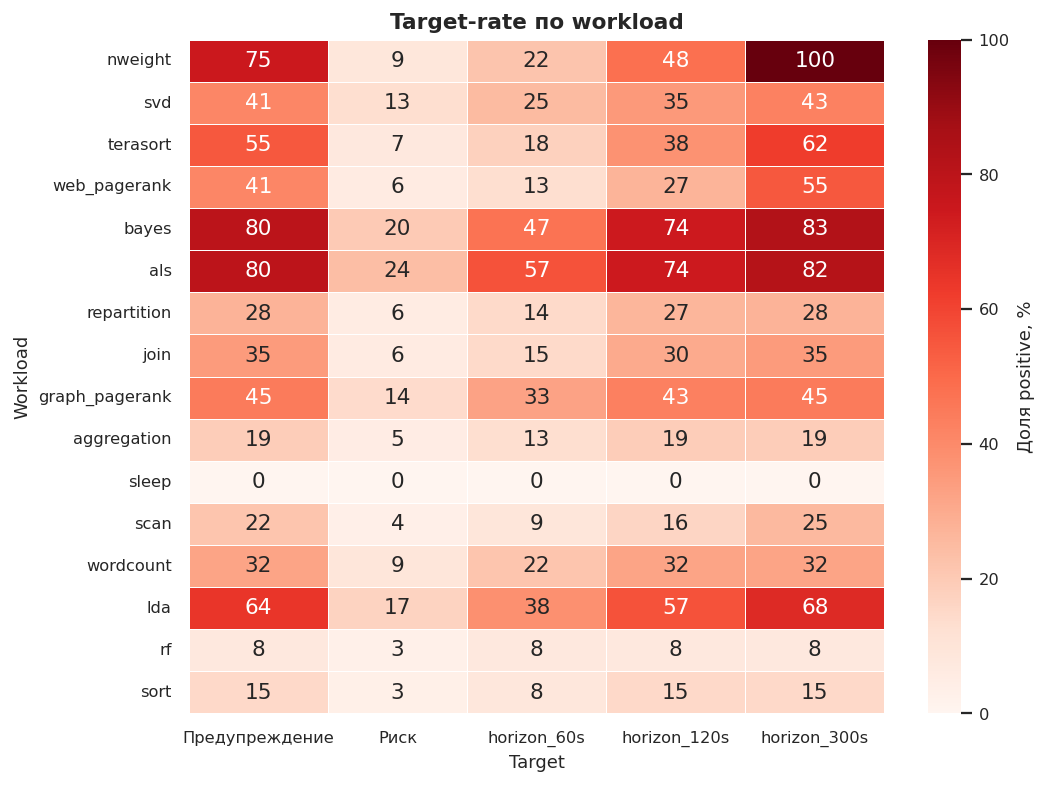

In [19]:
workload_target_cols = [
    c
    for c in ["y_warning", "eda_horizon_30s", "eda_horizon_60s", "eda_horizon_120s", "eda_horizon_300s"]
    if c in eda.columns
]
if workload_target_cols and "workload" in eda.columns:
    top_workloads = eda["workload"].value_counts().head(16).index
    workload_target = (
        eda[eda["workload"].isin(top_workloads)]
        .groupby("workload")[workload_target_cols]
        .mean()
        .loc[top_workloads]
    )
    workload_target = workload_target.rename(columns={c: target_label(c) for c in workload_target.columns})

    fig, ax = plt.subplots(figsize=(8.4, 6.2))
    sns.heatmap(
        workload_target * 100,
        annot=True,
        fmt=".0f",
        cmap="Reds",
        linewidths=0.45,
        linecolor="white",
        cbar_kws={"label": "Доля positive, %"},
        ax=ax,
    )
    ax.set_title("Доля положительных окон по типам нагрузки и целевым каналам")
    ax.set_xlabel("Целевой канал")
    ax.set_ylabel("Тип нагрузки")
    plt.tight_layout()
    plt.show()
else:
    print("Недостаточно колонок для workload-target анализа.")


Связь target с workload оказалась сильной. `sleep` практически не содержит positive-окон, `bayes` дает очень высокий `y_warning`, `als` выделяется на 60s horizon, а `nweight` почти полностью попадает в широкий 300s horizon. Такой рисунок означает, что workload несет не только контекст, но и сильный prior по вероятности события.

Это полезно, но опасно. Полезно - потому что AIOps-система действительно должна учитывать тип нагрузки. Опасно - потому что baseline может получить хороший score, просто угадав домен. Поэтому в `02` workload breakdown нужен не как дополнительная таблица, а как защита от самообмана: он покажет, где модель предсказывает событие, а где фактически узнает workload.


## 9. Предсобытийная динамика

Последняя проверка EDA отвечает на главный вопрос раннего предупреждения: виден ли сигнал до события, а не только после него. Здесь мы не ищем идеальный разделитель. Нам достаточно понять, появляются ли изменения в логах и KPI в окнах перед `fail_start` и насколько они шумны.

Если динамика есть, `02` получает смысловую задачу для baseline: простая модель должна поймать хотя бы часть этого сигнала. Если динамика слабая или нестабильная, это объясняет, почему короткие горизонты будут трудными и почему FP-control важнее красивой recall-цифры.


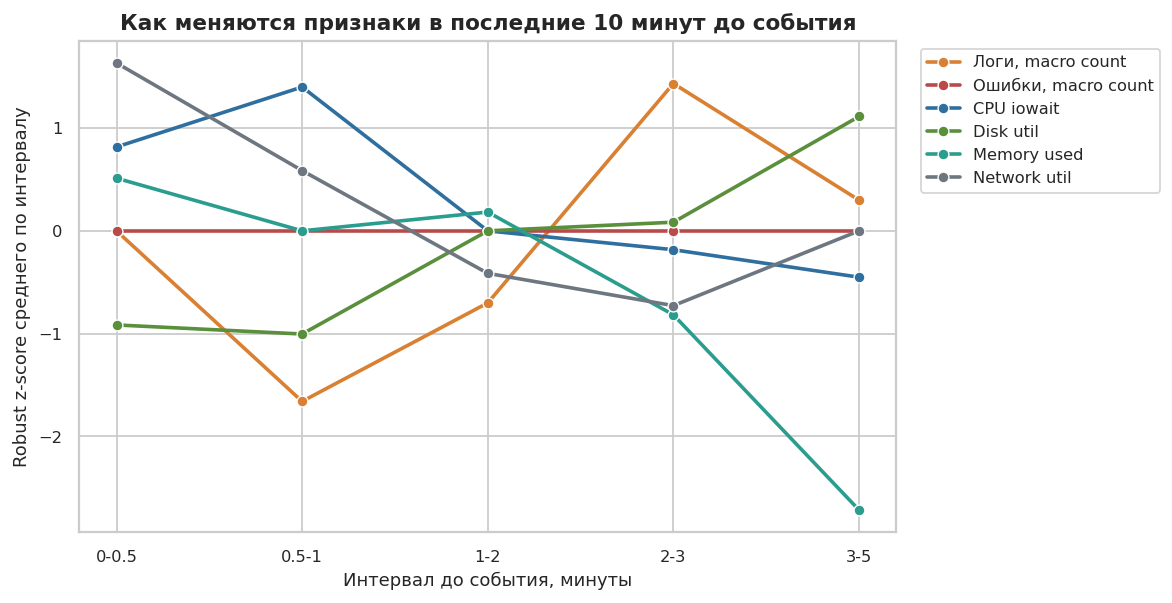

"Интервал до события, мин",Окна
0-0.5,291
0.5-1,380
1-2,457
2-3,286
3-5,203
5-10,0


In [20]:
if "minutes_before_fail" in eda.columns:
    pre = eda.copy()
    pre["minutes_before_fail"] = pd.to_numeric(pre["minutes_before_fail"], errors="coerce")
    pre = pre[pre["minutes_before_fail"].between(0, 10, inclusive="both")].copy()

    pre_features = []
    pre_labels = {}
    if "macro_log_count" in pre.columns:
        pre_features.append("macro_log_count")
        pre_labels["macro_log_count"] = "Логи, macro count"
    if "macro_error_count" in pre.columns:
        pre_features.append("macro_error_count")
        pre_labels["macro_error_count"] = "Ошибки, macro count"

    representative_tokens = {
        "cpustat__iowait__mean_dim__mean": "CPU iowait",
        "iostat__util__mean_dim__mean": "Disk util",
        "memstat__memused__mean_dim__mean": "Memory used",
        "netstat__ifutil__mean_dim__mean": "Network util",
    }
    for token, label in representative_tokens.items():
        matches = [c for c in kpi_cols if token in c]
        if matches:
            pre_features.append(matches[0])
            pre_labels[matches[0]] = label

    if not pre.empty and pre_features:
        bins = [0, 0.5, 1, 2, 3, 5, 10]
        labels = ["0-0.5", "0.5-1", "1-2", "2-3", "3-5", "5-10"]
        pre["До события, мин"] = pd.cut(pre["minutes_before_fail"], bins=bins, labels=labels, include_lowest=True)
        dynamics = pre.groupby("До события, мин", observed=False)[pre_features].mean(numeric_only=True)
        scaled = robust_scale_by_column(dynamics).reset_index().melt(
            id_vars="До события, мин", var_name="Признак", value_name="Относительный уровень"
        )
        scaled["Признак"] = scaled["Признак"].map(pre_labels)

        fig, ax = plt.subplots(figsize=(9.2, 4.8))
        sns.lineplot(
            data=scaled,
            x="До события, мин",
            y="Относительный уровень",
            hue="Признак",
            marker="o",
            linewidth=2,
            palette=[PALETTE["orange"], PALETTE["red"], PALETTE["blue"], PALETTE["green"], PALETTE["teal"], PALETTE["gray"]][: scaled["Признак"].nunique()],
            ax=ax,
        )
        ax.set_title("Как меняются признаки в последние 10 минут до события")
        ax.set_xlabel("Интервал до события, минуты")
        ax.set_ylabel("Робастный z-score среднего значения по интервалу")
        ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout()
        plt.show()

        support = pre["До события, мин"].value_counts().reindex(labels).rename_axis("Интервал до события, мин").reset_index(name="Окна")
        display(support.style.hide(axis="index"))
    else:
        print("Нет достаточного количества предсобытийных окон или признаков.")
else:
    print("Колонка minutes_before_fail отсутствует.")


Предсобытийная динамика есть, но она не выглядит как чистая монотонная лестница к сбою. В последних 0-0.5 минуты растут некоторые признаки вроде memory/network и macro log count по сравнению с рядом более ранних интервалов, но disk util, CPU iowait и логовые счетчики ведут себя неоднородно. Еще одна важная деталь - в текущей выборке почти нет окон дальше 5 минут до события в этом предсобытийном срезе, поэтому выводы про дальний warning надо делать осторожно.

Для `02` это означает, что baseline должен проверять не абстрактную "предсказуемость сбоя", а конкретный alert-смысл. На коротких горизонтах часть FN будет естественной: контекста мало, сигнал не всегда проявляется в одной модальности. Одновременно FP особенно вредны, потому что администратор увидит не график качества, а поток тревог. Поэтому validation threshold и FP-budget становятся частью исследовательского протокола, а не технической мелочью.


## Что именно `01` передает в `02`

После EDA мы все еще не выбираем финальную архитектуру. Но теперь требования к следующему notebook опираются не на ожидания, а на реальные свойства данных: split фактически завязан на workload, KPI почти всегда доступны, логи доступны заметно хуже, целевые каналы имеют разную плотность, а предсобытийный сигнал есть, но он шумный.

| Факт из данных | Что должно появиться в `02_baseline_pipeline.ipynb` | Почему это важно |
| --- | --- | --- |
| `raw_data/` содержит 16 неодинаковых workload и разные источники файлов | единый запуск `dashboard.pipeline.build_contract` и strict contract как вход baseline | чтобы baseline сравнивал модели, а не разные версии чтения raw-файлов |
| Текущий split во многом разделяет workload целиком | явный `split_protocol`, прежде всего `stratified_by_workload`, плюс split sanity checks | чтобы качество не измеряло только перенос между несмешанными доменами |
| KPI доступны примерно в 97% окон, logs - только примерно в 57%, обе модальности - примерно в 55% | `availability_only`, log-only, KPI-only и fused baseline families | чтобы отделить реальный сигнал от shortcut по доступности источника |
| KPI-профили заметно отличаются между workload | preprocessing / normalization step и признаки `raw_plus_deviation` | чтобы высокий нормальный уровень нагрузки не превращался в ложную тревогу |
| Короткие горизонты `30/60 с` заметно реже, чем `120/300 с` и `y_warning` | оценка каждого целевого канала отдельно | чтобы плотные каналы не маскировали сложность раннего предупреждения |
| Target-rate сильно зависит от workload | workload metrics и error breakdown | чтобы увидеть, где модель предсказывает событие, а где использует workload prior |
| Предсобытийная динамика есть, но не монотонна и не одинакова по модальностям | validation threshold, FP-budget, FP/FN counts | чтобы baseline оценивал пригодность alert-контура, а не только score |

Именно поэтому `02` должен быть в первую очередь notebook про pipeline. Baseline там нужен не как финальная модель, а как контрольный прибор: он проверяет, что данные собраны честно, split воспроизводим, целевые каналы доступны, thresholds выбираются на validation, а сохраненные predictions и metrics можно потом использовать для сравнения с финальным контуром.


## Итог 01

`01_eda.ipynb` фиксирует фактическую картину данных для диплома. Это не простая таблица для бинарной классификации: данные оконные, workload-зависимые, мультимодальные и неодинаковые по доступности источников. KPI-модальность почти всегда присутствует и дает богатое числовое описание, но ее масштабы сильно зависят от workload. Логовая модальность доступна существенно хуже и не дает простого монотонного сигнала через warning/error counts.

Target-часть тоже неоднородна. `warning/anomaly`, `risk` и горизонты 30/60/120/300s имеют разную плотность, а test отличается от train/validation по доле positive-окон. Дополнительно target-rate заметно зависит от workload: часть нагрузок почти не содержит positives, а часть резко выделяется по отдельным горизонтам. Это делает среднюю метрику потенциально обманчивой.

Главный результат этого notebook - не выбор модели, а набор ограничений для `02`. Следующий notebook должен доказать, что strict contract собирается воспроизводимо, split protocol выбран осознанно, preprocessing не прячет domain shift, baseline families действительно проверяют разные источники сигнала, а evaluation учитывает FP/FN и workload. Только после такого pipeline имеет смысл строить в `03` финальный облегченный мультимодальный контур предупреждения и обсуждать, оправдывает ли финальная мультимодальная архитектура свою сложность.
